In [ ]:
# ════════════════════════════════════════════════════════════════════
#  CÀI THƯ VIỆN CHO BÀI NÀY   (CAI THU VIEN CHO BAI NAY)
# ════════════════════════════════════════════════════════════════════
# Cell này chỉ cài những gói mà RIÊNG bài này cần, và chỉ cài gói nào
# đang thiếu. Nếu máy đã đủ thư viện thì nó không thay đổi gì.
#
# Phiên bản được chọn tự động theo Python đang chạy, vì pandas,
# scikit-learn và tensorflow không có bản dựng sẵn cho mọi phiên bản:
#     Python 3.10  →  bản đã dùng để tạo ra kết quả trong notebook này
#     Python 3.12  →  bản mới hơn, kết quả chạy lại có thể lệch nhẹ
import sys
from importlib.util import find_spec

PY312 = sys.version_info >= (3, 12)

# (tên module để kiểm tra, gói cho Python 3.10, gói cho Python 3.12)
REQUIRED = [
    ("numpy",     "numpy==1.26.4",         "numpy==1.26.4"),
    ("pandas",    "pandas==1.5.1",         "pandas==2.2.3"),
    ("sklearn",   "scikit-learn==1.2.0",   "scikit-learn==1.5.2"),
    ("matplotlib", "matplotlib==3.8.2",     "matplotlib==3.8.2"),
    ("seaborn",   "seaborn==0.13.1",       "seaborn==0.13.1"),
]

thieu = [(p312 if PY312 else p310) for mod, p310, p312 in REQUIRED
         if find_spec(mod) is None]

print(f"Python {sys.version.split()[0]}  |  bài này cần {len(REQUIRED)} gói")

if thieu:
    print("Đang cài", len(thieu), "gói còn thiếu:", ", ".join(thieu))
    try:
        from IPython import get_ipython
        _ip = get_ipython()
    except Exception:
        _ip = None
    if _ip is not None:
        _ip.run_line_magic("pip", "install --quiet " + " ".join(thieu))
    else:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                        *thieu], check=False)
    print("\n✅ Cài xong. Hãy KHỞI ĐỘNG LẠI KERNEL rồi chạy lại từ đầu.")
else:
    print("✅ Đã đủ thư viện, không cần cài gì thêm.\n")
    import importlib.metadata as _md
    for mod, p310, p312 in REQUIRED:
        ten = (p312 if PY312 else p310).split("==")[0].split(">=")[0]
        try:
            print(f"   {ten:<16} {_md.version(ten)}")
        except Exception:
            print(f"   {ten:<16} (không đọc được phiên bản)")


In [1]:
# ============================================================
# B3 - TÌM HIỂU BỘ DỮ LIỆU LƯU LƯỢNG MẠNG CỦA MÃ ĐỘC
# Dataset: CTU-13 Botnet Traffic
# ============================================================

# 1. IMPORT THƯ VIỆN
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.feature_selection import f_classif
from sklearn.ensemble import RandomForestClassifier
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

In [13]:
# 2. LOAD DATASET
root_folder = Path.cwd()
FILE_NORMAL = root_folder / "Dataset" / "CTU13" / "2017-04-28_normal.pcap_Flow.csv"
FILE_BOTNET = root_folder / "Dataset" / "CTU13" / "botnet-capture-20110810-neris.pcap_Flow.csv"

df_normal = pd.read_csv(FILE_NORMAL, low_memory=False)
df_botnet = pd.read_csv(FILE_BOTNET, low_memory=False)

df_normal['Label'] = 0
df_botnet['Label'] = 1
df = pd.concat([df_normal, df_botnet], axis=0, ignore_index=True)

print(f"Tổng số mẫu: {len(df):,}")
print(f"Normal: {len(df_normal):,}, Botnet: {len(df_botnet):,}")
print("Kích thước dataset:", df.shape)

print("\n5 dòng đầu tiên:")
print(df.head())

Tổng số mẫu: 40,651
Normal: 18,051, Botnet: 22,600
Kích thước dataset: (40651, 84)

5 dòng đầu tiên:
                                Flow ID          Src IP  Src Port  \
0       2.21.74.74-10.0.2.15-80-49157-6       10.0.2.15     49157   
1       2.21.74.74-10.0.2.15-80-49157-6       10.0.2.15     49157   
2    10.0.2.15-104.83.103.45-49164-80-6       10.0.2.15     49164   
3  216.58.207.174-10.0.2.15-443-49177-6       10.0.2.15     49177   
4  216.58.207.174-10.0.2.15-443-49177-6  216.58.207.174       443   

           Dst IP  Dst Port  Protocol               Timestamp  Flow Duration  \
0      2.21.74.74        80         6  31/12/1969 04:01:12 PM         216227   
1      2.21.74.74        80         6  31/12/1969 04:01:12 PM           1203   
2   104.83.103.45        80         6  31/12/1969 04:02:54 PM        1390444   
3  216.58.207.174       443         6  31/12/1969 04:02:56 PM         473666   
4       10.0.2.15     49177         6  31/12/1969 04:02:57 PM          31731   

   

In [3]:

# 3. XÓA CỘT KHÔNG CẦN THIẾT (metadata, IP, port, protocol)
drop_cols = []
for col in df.columns:
    if any(key in col for key in ['Timestamp', 'Flow ID', 'Src IP', 'Dst IP', 'Src Port', 'Dst Port', 'Protocol']):
        drop_cols.append(col)
drop_cols = list(set(drop_cols))
df.drop(columns=drop_cols, inplace=True)
print(f"Shape sau khi xóa: {df.shape}")

Shape sau khi xóa: (40651, 77)


In [4]:
# 4. ENCODE CỘT OBJECT VÀ XỬ LÝ MISSING
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = LabelEncoder().fit_transform(df[col].astype(str))

numeric_cols = df.select_dtypes(include=np.number).columns
for col in numeric_cols:
    df[col] = df[col].replace([np.inf, -np.inf], np.nan).fillna(df[col].median())


In [5]:
# 5. TÁCH X, y VÀ CHUẨN HÓA
X = df.drop(columns=['Label'])
y = df['Label']
scaler = MinMaxScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

print("Shape X:", X_scaled.shape)

Shape X: (40651, 76)


In [6]:
# 6. THỐNG KÊ MÔ TẢ
print("\nThống kê mô tả dữ liệu đã chuẩn hóa:")
print(X_scaled.describe())


Thống kê mô tả dữ liệu đã chuẩn hóa:
       Flow Duration  Tot Fwd Pkts  Tot Bwd Pkts  TotLen Fwd Pkts  \
count   40651.000000  40651.000000  40651.000000     40651.000000   
mean        0.102443      0.010259      0.001701         0.001475   
std         0.223594      0.043603      0.016073         0.026087   
min         0.000000      0.000000      0.000000         0.000000   
25%         0.000186      0.000000      0.000000         0.000000   
50%         0.002576      0.001570      0.000324         0.000000   
75%         0.075107      0.007849      0.000324         0.000091   
max         1.000000      1.000000      1.000000         1.000000   

       TotLen Bwd Pkts  Fwd Pkt Len Max  Fwd Pkt Len Min  Fwd Pkt Len Mean  \
count     40651.000000     40651.000000     40651.000000      40651.000000   
mean          0.000856         0.021644         0.002466          0.008612   
std           0.015321         0.071906         0.010326          0.029387   
min           0.000000      

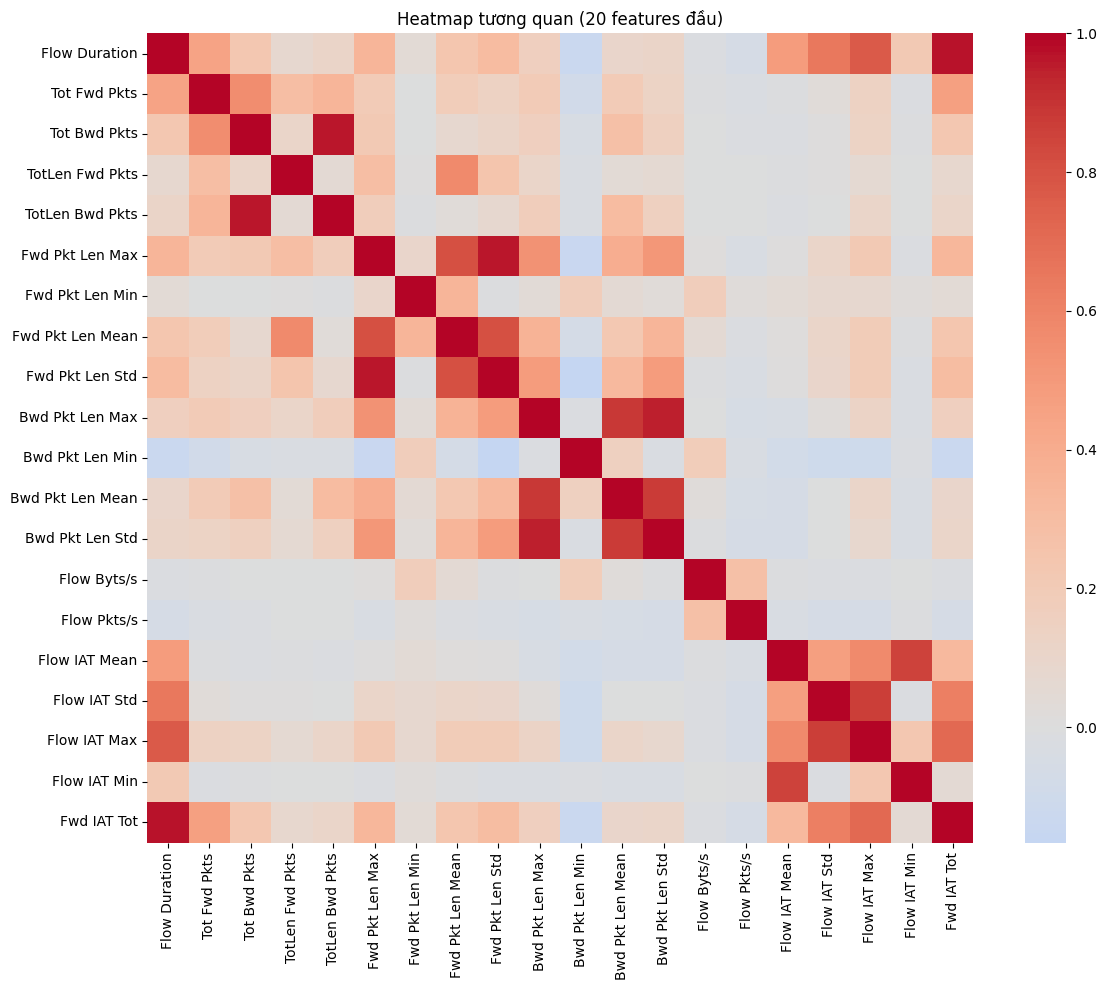

In [7]:
# 7. HEATMAP TƯƠNG QUAN (chỉ lấy 20 features đầu để dễ nhìn)
corr_matrix = X_scaled.corr()
plt.figure(figsize=(12,10))
sns.heatmap(corr_matrix.iloc[:20, :20], cmap='coolwarm', center=0, annot=False)
plt.title("Heatmap tương quan (20 features đầu)")
plt.tight_layout()
plt.show()

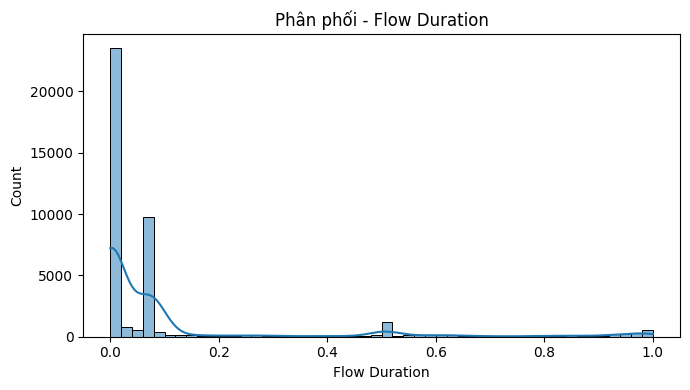

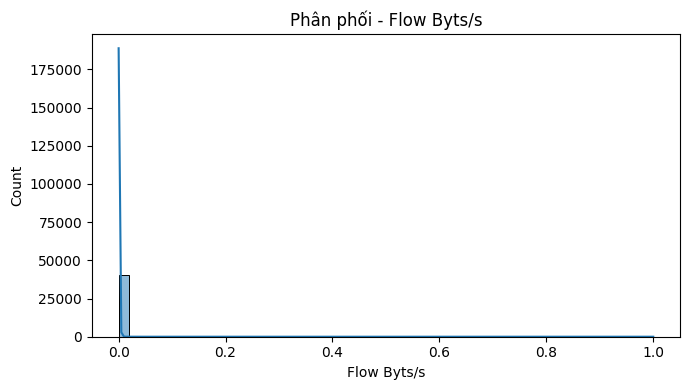

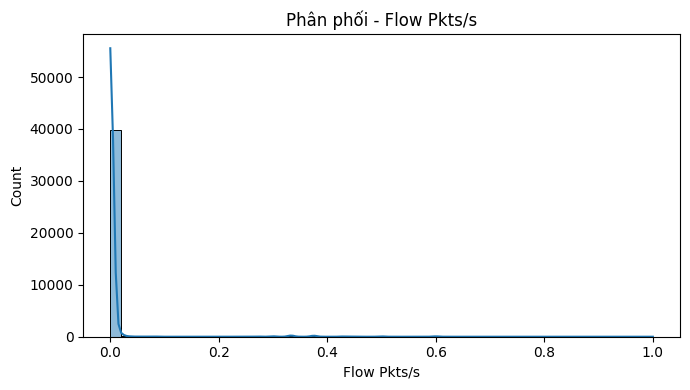

In [8]:
# 8. PHÂN PHỐI MỘT SỐ FEATURES QUAN TRỌNG
features_dist = ['Flow Duration', 'Flow Byts/s', 'Flow Pkts/s']
for feat in features_dist:
    if feat in X_scaled.columns:
        plt.figure(figsize=(7,4))
        sns.histplot(X_scaled[feat], bins=50, kde=True)
        plt.title(f'Phân phối - {feat}')
        plt.tight_layout()
        plt.show()

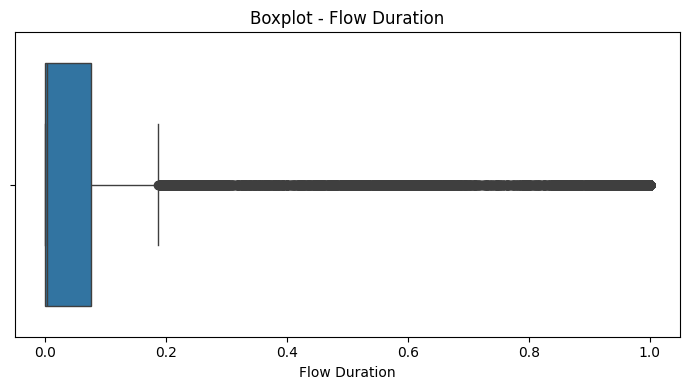

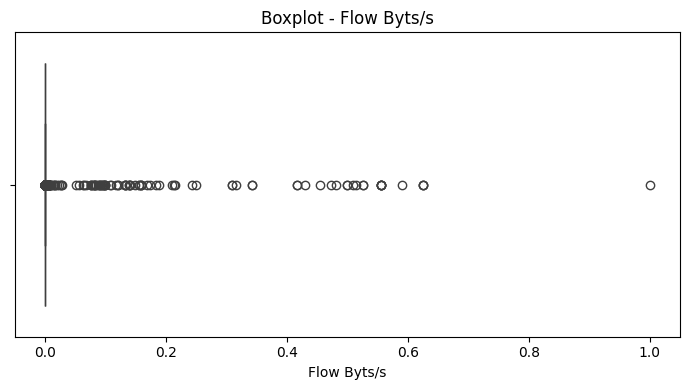

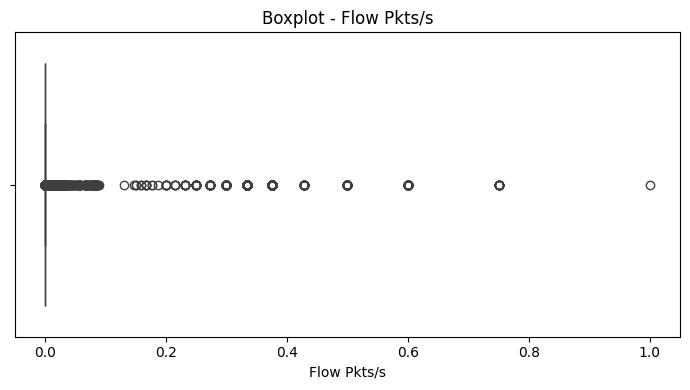

In [9]:
# 9. BOXPLOT PHÁT HIỆN OUTLIER
for feat in features_dist:
    if feat in X_scaled.columns:
        plt.figure(figsize=(7,4))
        sns.boxplot(x=X_scaled[feat])
        plt.title(f'Boxplot - {feat}')
        plt.tight_layout()
        plt.show()

In [10]:
# 10. ANOVA – ĐÁNH GIÁ TẦM QUAN TRỌNG FEATURE
f_values, p_values = f_classif(X_scaled, y)
feature_scores = pd.DataFrame({'Feature': X_scaled.columns, 'F_score': f_values, 'p_value': p_values})
feature_scores.sort_values('F_score', ascending=False, inplace=True)
print("\nTop 10 features theo ANOVA:")
print(feature_scores.head(10))


Top 10 features theo ANOVA:
              Feature       F_score  p_value
43       SYN Flag Cnt  10648.039805      0.0
37        Pkt Len Min   9671.413782      0.0
65  Init Bwd Win Byts   4275.448870      0.0
51       Pkt Size Avg   3825.027617      0.0
10    Bwd Pkt Len Min   3446.089000      0.0
71         Active Min   3245.993933      0.0
68        Active Mean   3168.128385      0.0
70         Active Max   2324.128727      0.0
39       Pkt Len Mean   1973.536212      0.0
6     Fwd Pkt Len Min   1647.030961      0.0


In [11]:
# 11. RANDOM FOREST FEATURE IMPORTANCE
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_scaled, y)
importance_df = pd.DataFrame({'Feature': X_scaled.columns, 'Importance': rf.feature_importances_})
importance_df.sort_values('Importance', ascending=False, inplace=True)
print("\nTop 10 features theo Random Forest:")
print(importance_df.head(10))


Top 10 features theo Random Forest:
              Feature  Importance
18       Flow IAT Min    0.097170
16       Flow IAT Std    0.084721
35         Fwd Pkts/s    0.073531
33     Fwd Header Len    0.065334
1        Tot Fwd Pkts    0.063797
65  Init Bwd Win Byts    0.062807
0       Flow Duration    0.030751
60   Subflow Fwd Pkts    0.029425
36         Bwd Pkts/s    0.027578
50      Down/Up Ratio    0.025013


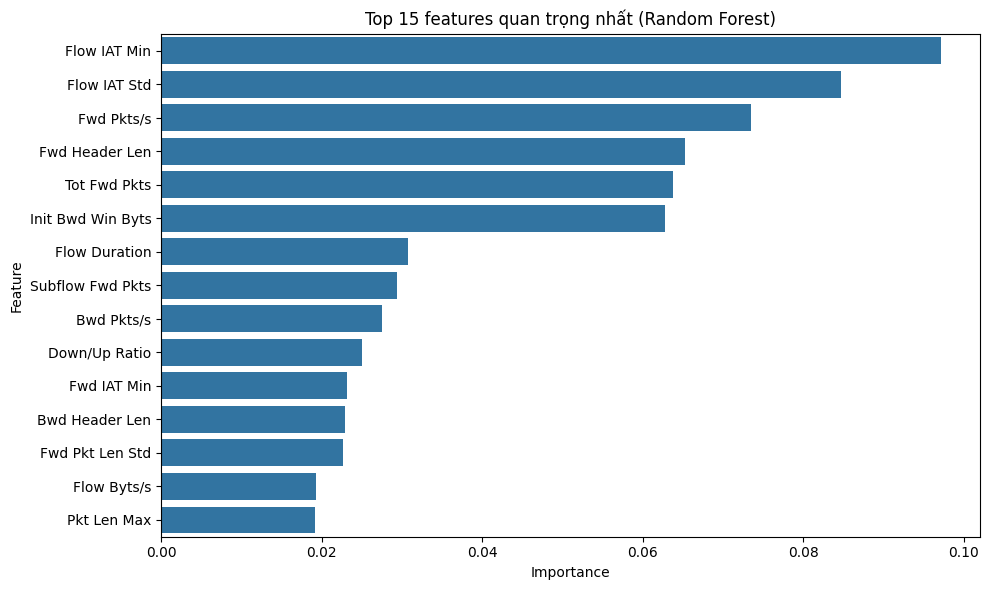

In [12]:
# 12. TRỰC QUAN HÓA FEATURE IMPORTANCE
plt.figure(figsize=(10,6))
sns.barplot(data=importance_df.head(15), x='Importance', y='Feature')
plt.title("Top 15 features quan trọng nhất (Random Forest)")
plt.tight_layout()
plt.show()